# MIS 5480: Recommendations and Engagement
## Group 4 | KuaiRand-Pure
Question: How does observed engagement differ between regular recommendations and randomly shown videos?

This is a descriptive analysis of short-video platform Kuaishou. The two files cover April 22-May 8, 2022. The "Pure" dataset retains a restricted candidate video pool. We compare one shared feed setting (tab = 1), the setting with the most observations in both groups.

In [2]:
import os
# set working directory
os.chdir(r"C:\Users\taylo\OneDrive\Documents\Grad School\MIS 5480\Group Project")
print(os.getcwd())

C:\Users\taylo\OneDrive\Documents\Grad School\MIS 5480\Group Project


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

regular = pd.read_csv("KuaiRand-Pure/data/log_standard_4_22_to_5_08_pure.csv")
random = pd.read_csv("KuaiRand-Pure/data/log_random_4_22_to_5_08_pure.csv")

print("Regular rows and columns:", regular.shape)
print("Random rows and columns:", random.shape)
print("Column names:", regular.columns.tolist())

Regular rows and columns: (295497, 19)
Random rows and columns: (1186059, 19)
Column names: ['user_id', 'video_id', 'date', 'hourmin', 'time_ms', 'is_click', 'is_like', 'is_follow', 'is_comment', 'is_forward', 'is_hate', 'long_view', 'play_time_ms', 'duration_ms', 'profile_stay_time', 'comment_stay_time', 'is_profile_enter', 'is_rand', 'tab']


## Step 1: Inspect and check the data
Each row is a logged video appearance and response. Users can appear many times. **is_like** is 1 for a like and 0 otherwise. **long_view** is 1 for watching the full duration when a video is at most 18 seconds, or at least 18 seconds for a longer video. **tab** identifies the feed setting. **is_rand** identifies random intervention. A zero does not necessarily mean dislike.

We inspect only the fields needed for this analysis. No missing values were found in the selected fields, so no rows were removed for missing data.

In [4]:
columns = ["user_id", "video_id", "date", "tab",
           "is_rand", "is_like", "long_view"]
regular = regular[columns].copy()
random = random[columns].copy()

print("First 5 regular records:")
print(regular.head().to_string(index=False))
print("\nData types:")
print(regular.dtypes)
print("\nMissing values in selected fields:")
print(pd.DataFrame({"Regular": regular.isna().sum(),
                    "Random": random.isna().sum()}))
print("\nRegular exposure labels:", regular["is_rand"].unique())
print("Random exposure labels:", random["is_rand"].unique())
for column in ["is_like", "long_view"]:
    print(column, "regular:", regular[column].unique(),
          "random:", random[column].unique())

First 5 regular records:
 user_id  video_id     date  tab  is_rand  is_like  long_view
       0      7531 20220422    0        0        0          0
       0      4214 20220425    1        0        0          0
       0      3978 20220429    0        0        0          0
       0       160 20220430    1        0        0          0
       0      6946 20220502    1        0        0          0

Data types:
user_id      int64
video_id     int64
date         int64
tab          int64
is_rand      int64
is_like      int64
long_view    int64
dtype: object

Missing values in selected fields:
           Regular  Random
user_id          0       0
video_id         0       0
date             0       0
tab              0       0
is_rand          0       0
is_like          0       0
long_view        0       0

Regular exposure labels: [0]
Random exposure labels: [1]
is_like regular: [0 1] random: [0 1]
long_view regular: [0 1] random: [0 1]


## Step 2: Prepare Shared Comparison
Label the groups, combine the files, and keep tab = 1. This avoids mixing different feed settings. It does not make the groups identical in users or videos. The missing-value and binary-label checks above show whether the selected fields are ready for analysis and it was found that no missing-value removal is needed for these supplied files.

In [5]:
regular["exposure"] = "Regular"
random["exposure"] = "Random"
data = pd.concat([regular, random], ignore_index=True)

print("Counts before filtering:")
print(pd.crosstab(data["tab"], data["exposure"]))

comparison = data[data["tab"] == 1].copy()
print("\nDate range:", comparison["date"].min(),
      "to", comparison["date"].max())
print("\nRows retained:", len(comparison))

Counts before filtering:
exposure   Random  Regular
tab                       
0               0    28074
1         1178025   223513
2             764     9073
3               0      440
4               0    17641
5               0      767
6               0    13114
7               0      171
8               0     1358
9               0      192
10              0       72
11           6755      308
12              0      638
13              0      116
14            515       20

Date range: 20220422 to 20220508

Rows retained: 1401538


## Step 3: Summarize Engagement
For a binary 0/1 field, its mean is the proportion of rows = 1. Multiplying by 100 gives a percentage. These rates use video appearances as the denominator, not unique users. Counts are included because the two groups have different sizes.

In [6]:
summary = comparison.groupby("exposure").agg(
    appearances=("video_id", "size"),
    users=("user_id", "nunique"),
    likes=("is_like", "sum"),
    long_views=("long_view", "sum"),
    like_rate=("is_like", "mean"),
    long_view_rate=("long_view", "mean")
)
summary["like_percent"] = summary["like_rate"] * 100
summary["long_view_percent"] = summary["long_view_rate"] * 100

print(summary[["appearances", "users", "likes", "long_views"]].to_string())
print("\nEngagement percentages:")
print(summary[["like_percent", "long_view_percent"]].round(2).to_string())

          appearances  users  likes  long_views
exposure                                       
Random        1178025  27000   5672      100542
Regular        223513  24537   4477       78592

Engagement percentages:
          like_percent  long_view_percent
exposure                                 
Random            0.48               8.53
Regular           2.00              35.16


# Step 4: Visualize the Results

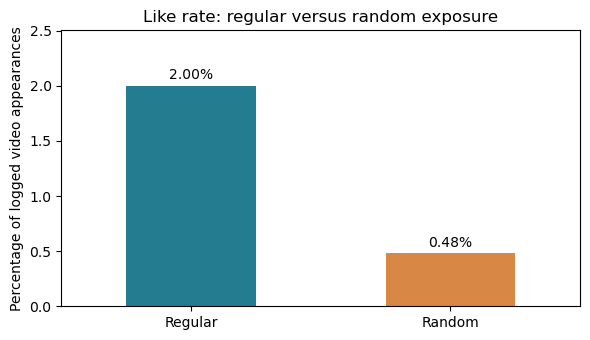

In [7]:
values = summary.reindex(["Regular", "Random"])["like_percent"]
ax = values.plot.bar(color=["#247C91", "#D88745"], figsize=(6, 3.5))
ax.set_title("Like rate: regular versus random exposure")
ax.set_ylabel("Percentage of logged video appearances")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.set_ylim(0, values.max() * 1.25)
for position, value in enumerate(values):
    ax.text(position, value + values.max() * 0.03,
            f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

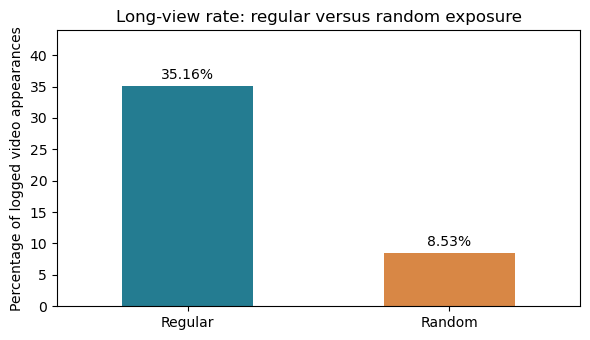

In [8]:
values = summary.reindex(["Regular", "Random"])["long_view_percent"]
ax = values.plot.bar(color=["#247C91", "#D88745"], figsize=(6, 3.5))
ax.set_title("Long-view rate: regular versus random exposure")
ax.set_ylabel("Percentage of logged video appearances")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.set_ylim(0, values.max() * 1.25)
for position, value in enumerate(values):
    ax.text(position, value + values.max() * 0.03,
            f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

## Step 5: Findings and Analysis
In feed setting 1, regular recommendations received likes on 2% of appearances, compared with 0.48% for randomly shown videos. Long views occurred on 35.16% and 8.53%, respectively. These are observed differences in engagement, not proof that recommendations changed preferences.

# Connection to our proposal: 
Our proposal explores how recommendations can shape behavior that becomes input for future recommendations. In our sample, regular recommendations received higher like and long-view rates than randomly shown videos. This connects to the feedback-loop question because the engagement data a platform collects depends partly on which content it chooses to show. Those records reflect responses to a selected set of opportunities, rather than a complete picture of users’ interests.

If a system uses that engagement to recommend more similar content, it could reinforce earlier predictions: selected content receives exposure, exposure produces engagement, and engagement informs later selections. Our results illustrate the exposure-and-response portion of this possible loop. They do not demonstrate that the system increased similar recommendations afterward or changed users’ preferences.

For businesses, this highlights a challenge in interpreting engagement metrics: higher engagement may indicate successful personalization, but it does not establish that users’ interests are becoming broader or that their long-term satisfaction is improving.

## Sources
**Dataset & field defintions:** https://kuairand.com/

**Dataset Paper:** Gao et al. (2022), KuaiRand: An Unbiased Sequential Recommendation Dataset with Randomly Exposed Videos. https://arxiv.org/abs/2208.08696